### Project 3: Smoke Season Tracker (Marshall, MN vs. Moorhead, MN)

## Step 1: Extract Data and do Setup
This cell requests latitude and longitude coordinates for **Marshall, MN** and **Moorhead, MN** using the Open-Meteo Geocoding API. Geocoding is an essential first step in our data pipeline because the subsequent Air Quality and Historical Weather APIs require precise geographic coordinates rather than city names. To ensure we choose the correct location among multiple cities with the same name, we filter our requests specifically searching for the state of Minnesota (MN) in the United States. We expect to retrieve and print coordinates (latitude and longitude) for both cities.

In [1]:
import requests
import json
import pandas as pd
import time

def geocode_city(city_name):
    url = "https://geocoding-api.open-meteo.com/v1/search"
    params = {
        "name": city_name,
        "count": 10,
        "language": "en",
        "format": "json"
    }
    response = requests.get(url, params=params)
    if response.status_code == 200:
        data = response.json()
        results = data.get("results", [])
        # Filter for Minnesota, USA
        for res in results:
            admin1 = res.get("admin1", "")
            country = res.get("country", "")
            if (admin1 == "Minnesota" or admin1 == "MN") and country == "United States":
                return {
                    "name": res["name"],
                    "latitude": res["latitude"],
                    "longitude": res["longitude"],
                    "timezone": res.get("timezone", "America/Chicago")
                }
        # Fallback to first result if MN is not explicitly matched
        if results:
            return {
                "name": results[0]["name"],
                "latitude": results[0]["latitude"],
                "longitude": results[0]["longitude"],
                "timezone": results[0].get("timezone", "America/Chicago")
            }
    return None

cities = ["Marshall", "Moorhead"]
coordinates = {}

for city in cities:
    info = geocode_city(city)
    if info:
        coordinates[city] = info
        print(f"Found: {city} -> Latitude: {info['latitude']}, Longitude: {info['longitude']}, Timezone: {info['timezone']}")
    else:
        print(f"Could not find coordinates for {city}")
    time.sleep(1) # Be polite to API

Found: Marshall -> Latitude: 44.4469, Longitude: -95.78835, Timezone: America/Chicago
Found: Moorhead -> Latitude: 46.87386, Longitude: -96.76951, Timezone: America/Chicago


After running the cell we found the latitude, longitude, and timezone for Marshall, MN and Moorhead, MN.

## Steps 2, 3: Fetch and Store Raw API Data
This cell requests historical hourly air quality metrics and daily weather metrics for Marshall and Moorhead for the summers of 2023 to 2026. It also defines the data with respect to rate and size limits saving the raw responses directly to disk as local JSON files so we do not hit the API every time the notebook is run. We expect to see confirmation of successfull files saved.

In [2]:
import os

# Create raw data folder if it doesn't exist
os.makedirs("data/raw", exist_ok=True)

years = [2023, 2024, 2025, 2026]
city_coords = {
    "Marshall": {"lat": 44.4469, "lon": -95.78835},
    "Moorhead": {"lat": 46.87386, "lon": -96.76951}
}

# Fetch and cache raw data
for city_name, coords in city_coords.items():
    for year in years:
        start_date = f"{year}-06-01"
        end_date = f"{year}-09-30"

        # 1. Fetch Air Quality Data
        aq_url = "https://air-quality-api.open-meteo.com/v1/air-quality"
        aq_params = {
            "latitude": coords["lat"],
            "longitude": coords["lon"],
            "hourly": "pm2_5,us_aqi,us_aqi_pm2_5,aerosol_optical_depth",
            "start_date": start_date,
            "end_date": end_date,
            "timezone": "America/Chicago"
        }

        aq_resp = requests.get(aq_url, params=aq_params)
        if aq_resp.status_code == 200:
            filename = f"data/raw/aq_{city_name.lower()}_{year}.json"
            with open(filename, "w") as f:
                json.dump(aq_resp.json(), f)
            print(f"Saved: {filename}")
        else:
            print(f"Error fetching AQ for {city_name} in {year}: Status {aq_resp.status_code}")

        time.sleep(1)

        # 2. Fetch Historical Weather Data
        weather_url = "https://archive-api.open-meteo.com/v1/archive"
        weather_params = {
            "latitude": coords["lat"],
            "longitude": coords["lon"],
            "daily": "precipitation_sum,temperature_2m_max,wind_speed_10m_max,wind_direction_10m_dominant",
            "start_date": start_date,
            "end_date": end_date,
            "timezone": "America/Chicago"
        }

        weather_resp = requests.get(weather_url, params=weather_params)
        if weather_resp.status_code == 200:
            filename = f"data/raw/weather_{city_name.lower()}_{year}.json"
            with open(filename, "w") as f:
                json.dump(weather_resp.json(), f)
            print(f"Saved: {filename}")
        else:
            print(f"Error fetching Weather for {city_name} in {year}: Status {weather_resp.status_code}")

        time.sleep(1)

Saved: data/raw/aq_marshall_2023.json
Saved: data/raw/weather_marshall_2023.json
Saved: data/raw/aq_marshall_2024.json
Saved: data/raw/weather_marshall_2024.json
Saved: data/raw/aq_marshall_2025.json
Saved: data/raw/weather_marshall_2025.json
Saved: data/raw/aq_marshall_2026.json
Saved: data/raw/weather_marshall_2026.json
Saved: data/raw/aq_moorhead_2023.json
Saved: data/raw/weather_moorhead_2023.json
Saved: data/raw/aq_moorhead_2024.json
Saved: data/raw/weather_moorhead_2024.json
Saved: data/raw/aq_moorhead_2025.json
Saved: data/raw/weather_moorhead_2025.json
Saved: data/raw/aq_moorhead_2026.json
Saved: data/raw/weather_moorhead_2026.json


After running the cell, we got confirmation of the saved files.

In this cell we will put our cleaned data into a database and save it as a CSV file. This is necessary because it allows for the data to be retrieved later and used to make the future charts. We are using the built-in functions for python.

## Steps 4,5,6: Transform, Clean, and Store Clean Data (SQLite & CSV)
This cell parses the raw JSON files we saved in Step 2, we also put our cleaned data into a database and save it as a CSV file. This is necessary because it allows for the data to be retrieved later and used to make the future charts. We are using the built-in functions for python. We expect to see the successful creation of the database tables and the final shapes/record counts of our clean datasets.

In [3]:
import sqlite3

# Create clean folder if it doesn't exist
os.makedirs("data/clean", exist_ok=True)

all_daily_records = []

for city_name in ["Marshall", "Moorhead"]:
    for year in [2023, 2024, 2025, 2026]:
        aq_path = f"data/raw/aq_{city_name.lower()}_{year}.json"
        weather_path = f"data/raw/weather_{city_name.lower()}_{year}.json"

        # Load AQ
        with open(aq_path, "r") as f:
            aq_data = json.load(f)

        hourly = aq_data["hourly"]
        times = hourly["time"]
        pm2_5 = hourly["pm2_5"]
        us_aqi = hourly["us_aqi"]
        us_aqi_pm2_5 = hourly["us_aqi_pm2_5"]
        aod = hourly["aerosol_optical_depth"]

        # Verify list lengths match
        assert len(times) == len(pm2_5) == len(us_aqi) == len(us_aqi_pm2_5) == len(aod), f"Mismatch in AQ list lengths for {city_name} {year}"

        # Build a temporary DataFrame
        df_hourly = pd.DataFrame({
            "datetime": pd.to_datetime(times),
            "pm2_5": pm2_5,
            "us_aqi": us_aqi,
            "us_aqi_pm2_5": us_aqi_pm2_5,
            "aerosol_optical_depth": aod
        })

        # Extract date from datetime for grouping
        df_hourly["date"] = df_hourly["datetime"].dt.date

        # Check missing hours per day. Drop days with >6 missing hours (75% availability needed)
        valid_days = df_hourly.groupby("date").agg(
            count_hours=("pm2_5", "count"),
            pm2_5_mean=("pm2_5", "mean"),
            us_aqi_mean=("us_aqi", "mean"),
            us_aqi_pm2_5_mean=("us_aqi_pm2_5", "mean"),
            aod_mean=("aerosol_optical_depth", "mean")
        ).reset_index()

        # Filter out days with less than 18 valid hours (75% of 24 hours)
        valid_days = valid_days[valid_days["count_hours"] >= 18]

        # Load Weather
        with open(weather_path, "r") as f:
            weather_data = json.load(f)

        daily = weather_data["daily"]
        df_weather = pd.DataFrame({
            "date": pd.to_datetime(daily["time"]).map(lambda x: x.date()),
            "precipitation_sum": daily["precipitation_sum"],
            "temperature_2m_max": daily["temperature_2m_max"],
            "wind_speed_10m_max": daily["wind_speed_10m_max"],
            "wind_direction_10m_dominant": daily["wind_direction_10m_dominant"]
        })

        # Merge AQ and Weather
        df_merged = pd.merge(valid_days, df_weather, on="date", how="inner")
        df_merged["city"] = city_name
        all_daily_records.append(df_merged)

# Combine all years and cities
df_clean = pd.concat(all_daily_records, ignore_index=True)

# Ensure date column is standard string format for compatibility
df_clean["date"] = df_clean["date"].astype(str)

# Save to SQLite
conn = sqlite3.connect("data/smoke_tracker.db")
df_clean.to_sql("smoke_data", conn, if_exists="replace", index=False)
conn.close()

# Save to CSV
df_clean.to_csv("data/clean/smoke_days.csv", index=False)

print(f"Database 'data/smoke_tracker.db' saved and updated successfully.")
print(f"Clean CSV exported successfully with {df_clean.shape[0]} rows and {df_clean.shape[1]} columns.")

Database 'data/smoke_tracker.db' saved and updated successfully.
Clean CSV exported successfully with 976 rows and 11 columns.


## Step 7: Smoke Metrics and City Comparison Analysis and Visualization
This cell computes the specific wildfire-smoke metrics, while the next cell uses the metrics to create charts. We expect to see dataframes outlining these comparisons side-by-side and charts that visualize the differences as well.

In [4]:
import numpy as np

# Load clean dataset from CSV
df_analysis = pd.read_csv("data/clean/smoke_days.csv")
df_analysis["date"] = pd.to_datetime(df_analysis["date"])
df_analysis["year"] = df_analysis["date"].dt.year

# Define thresholds
SMOKE_THRESHOLD = 35.5
MODERATE_THRESHOLD = 9.0

# Tag smoke days
df_analysis["is_smoke_day"] = df_analysis["pm2_5_mean"] >= SMOKE_THRESHOLD
df_analysis["is_mod_smoke_day"] = df_analysis["pm2_5_mean"] > MODERATE_THRESHOLD

# Define a helper function to calculate the longest consecutive streak of true values
def longest_streak(bool_series):
    streak = 0
    max_streak = 0
    for val in bool_series:
        if val:
            streak += 1
            max_streak = max(max_streak, streak)
        else:
            streak = 0
    return max_streak

# Create summary lists
summary_stats = []

for city in ["Marshall", "Moorhead"]:
    df_city = df_analysis[df_analysis["city"] == city].sort_values("date")

    for year in [2023, 2024, 2025, 2026]:
        df_city_year = df_city[df_city["year"] == year]

        # Counts
        smoke_days_count = df_city_year["is_smoke_day"].sum()
        mod_days_count = df_city_year["is_mod_smoke_day"].sum()

        # Worst day
        if not df_city_year.empty:
            worst_idx = df_city_year["pm2_5_mean"].idxmax()
            worst_day_row = df_city_year.loc[worst_idx]
            worst_date = worst_day_row["date"].strftime("%Y-%m-%d")
            worst_pm25 = round(worst_day_row["pm2_5_mean"], 2)
        else:
            worst_date, worst_pm25 = None, 0.0

        # Consecutive run
        consec_run = longest_streak(df_city_year["is_smoke_day"])

        summary_stats.append({
            "City": city,
            "Year": year,
            "Smoke Days (>=35.5)": smoke_days_count,
            "Moderate Days (>9.0)": mod_days_count,
            "Worst Day (Date)": worst_date,
            "Worst Day PM2.5": worst_pm25,
            "Longest Streak (Days)": consec_run
        })

df_summary = pd.DataFrame(summary_stats)
print("=== SMOKE STATISTICS SUMMARY ===")
print(df_summary.to_string(index=False))

# Check overlapping smoke days
marshall_smoke_dates = set(df_analysis[(df_analysis["city"] == "Marshall") & (df_analysis["is_smoke_day"] == True)]["date"])
moorhead_smoke_dates = set(df_analysis[(df_analysis["city"] == "Moorhead") & (df_analysis["is_smoke_day"] == True)]["date"])

shared_dates = marshall_smoke_dates.intersection(moorhead_smoke_dates)
print(f"\nShared Extreme Smoke Days: {len(shared_dates)}")
if len(shared_dates) > 0:
    print(f"Dates: {[d.strftime('%Y-%m-%d') for d in sorted(shared_dates)]}")

=== SMOKE STATISTICS SUMMARY ===
    City  Year  Smoke Days (>=35.5)  Moderate Days (>9.0) Worst Day (Date)  Worst Day PM2.5  Longest Streak (Days)
Marshall  2023                    3                    78       2023-06-15            55.34                      2
Marshall  2024                    0                    57       2024-07-23            33.16                      0
Marshall  2025                    1                    33       2025-06-01            59.84                      1
Marshall  2026                    0                     9       2026-07-28            16.85                      0
Moorhead  2023                    1                    88       2023-06-14            37.72                      1
Moorhead  2024                    3                    56       2024-07-23            46.49                      3
Moorhead  2025                    3                    41       2025-06-01            79.64                      2
Moorhead  2026                    0            

=== WEATHER ASSOCIATION ON SMOKE DAYS VS NORMAL DAYS ===

--- Marshall ---
  Extreme Smoke Days (N=4):
    Average Rain: 0.03 mm
    Average Max Wind Speed: 18.35 km/h
    Dominant Wind Dir (Mean): 155.2°
  Normal Days (N=484):
    Average Rain: 3.43 mm
    Average Max Wind Speed: 19.98 km/h
    Dominant Wind Dir (Mean): 199.5°

--- Moorhead ---
  Extreme Smoke Days (N=7):
    Average Rain: 0.96 mm
    Average Max Wind Speed: 16.66 km/h
    Dominant Wind Dir (Mean): 166.9°
  Normal Days (N=481):
    Average Rain: 2.81 mm
    Average Max Wind Speed: 19.28 km/h
    Dominant Wind Dir (Mean): 191.9°


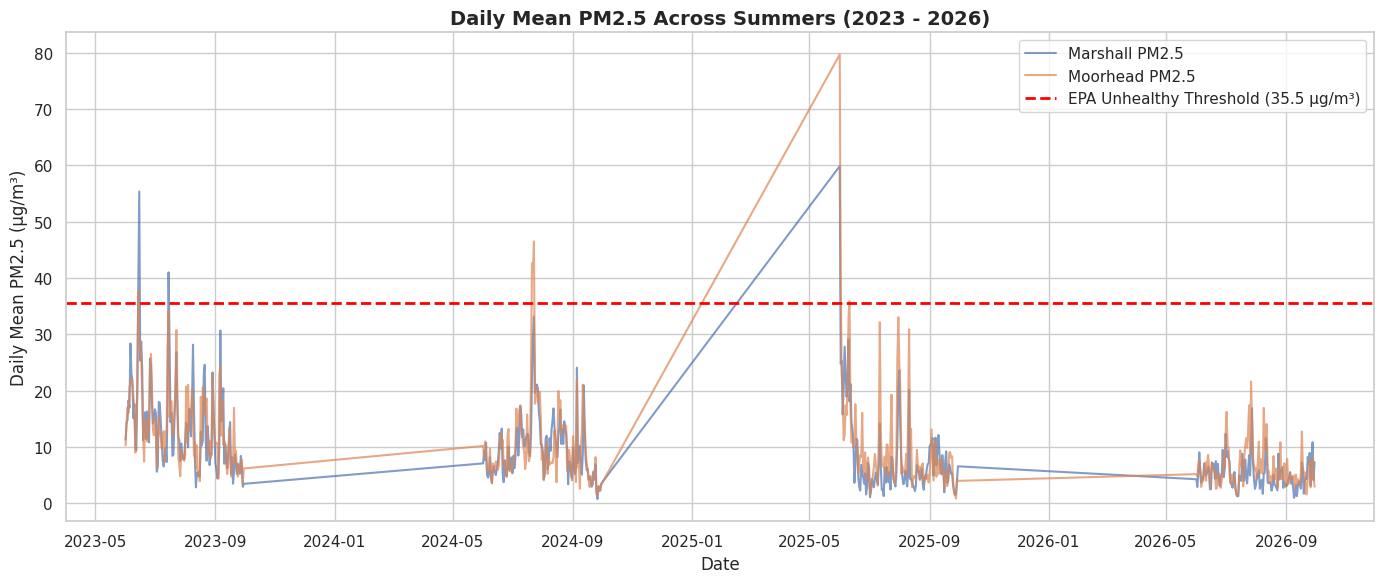

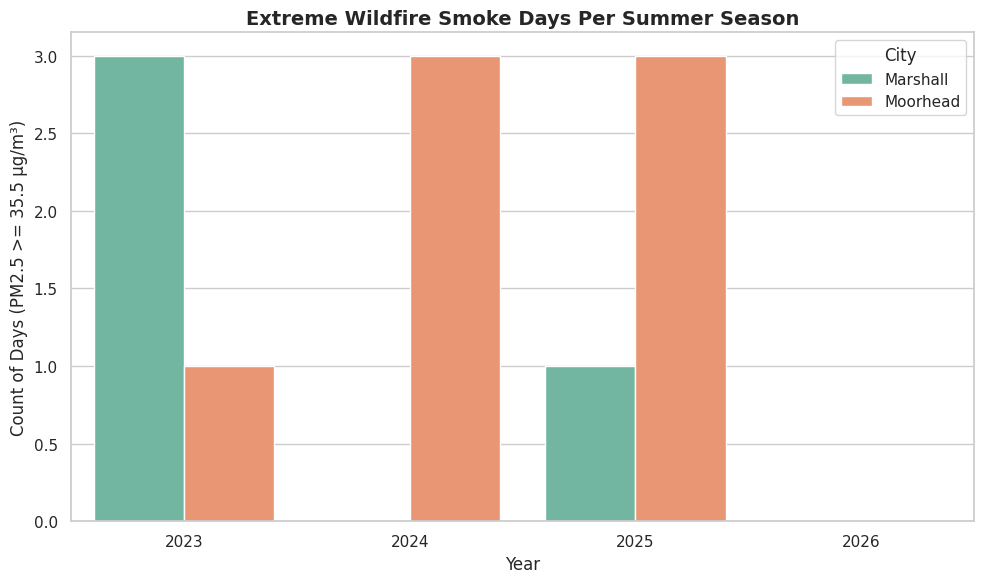

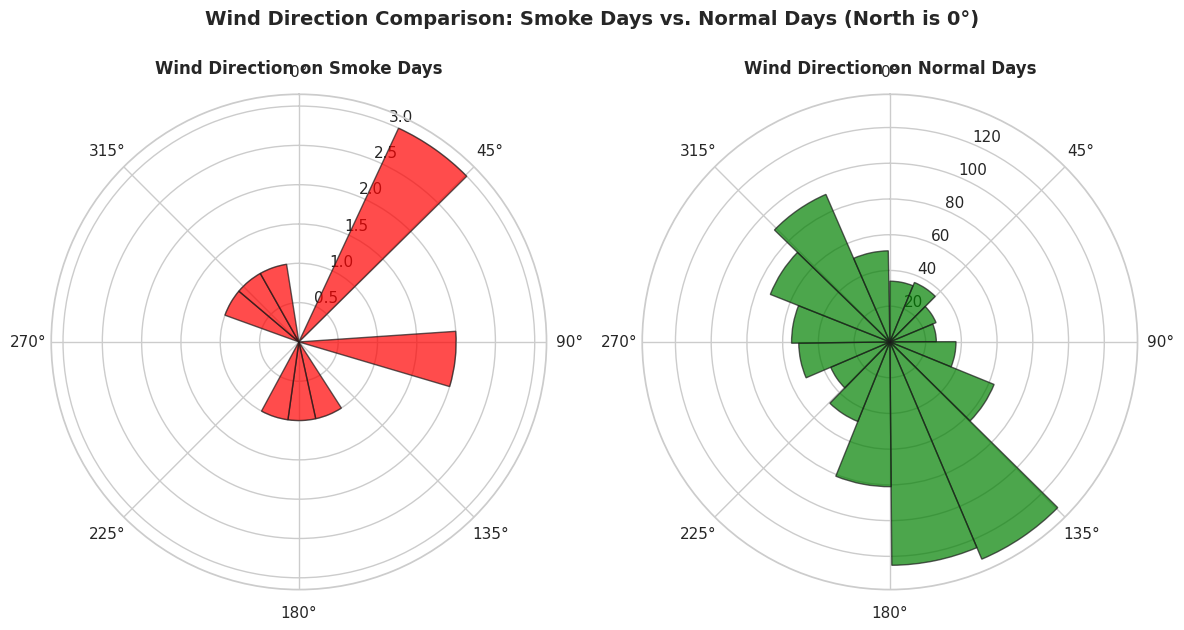

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create charts directory
os.makedirs("charts", exist_ok=True)
sns.set_theme(style="whitegrid")

# --- 1. Weather Correlation Statistics ---
print("=== WEATHER ASSOCIATION ON SMOKE DAYS VS NORMAL DAYS ===")
for city in ["Marshall", "Moorhead"]:
    df_city = df_analysis[df_analysis["city"] == city]
    print(f"\n--- {city} ---")
    for is_smoke in [True, False]:
        subset = df_city[df_city["is_smoke_day"] == is_smoke]
        label = "Extreme Smoke Days" if is_smoke else "Normal Days"
        print(f"  {label} (N={len(subset)}):")
        print(f"    Average Rain: {subset['precipitation_sum'].mean():.2f} mm")
        print(f"    Average Max Wind Speed: {subset['wind_speed_10m_max'].mean():.2f} km/h")
        print(f"    Dominant Wind Dir (Mean): {subset['wind_direction_10m_dominant'].mean():.1f}°")

# --- 2. Chart 1: Daily Mean PM2.5 Timeline ---
plt.figure(figsize=(14, 6))
for city in ["Marshall", "Moorhead"]:
    df_city = df_analysis[df_analysis["city"] == city].sort_values("date")
    plt.plot(df_city["date"], df_city["pm2_5_mean"], label=f"{city} PM2.5", alpha=0.7)

plt.axhline(y=35.5, color="red", linestyle="--", linewidth=2, label="EPA Unhealthy Threshold (35.5 µg/m³)")
plt.title("Daily Mean PM2.5 Across Summers (2023 - 2026)", fontsize=14, fontweight='bold')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Daily Mean PM2.5 (µg/m³)", fontsize=12)
plt.legend()
plt.tight_layout()
plt.savefig("charts/pm25_timeline.png", dpi=300)
plt.show()

# --- 3. Chart 2: Smoke Days Per Summer Grouped Bar Chart ---
plt.figure(figsize=(10, 6))
sns.barplot(data=df_summary, x="Year", y="Smoke Days (>=35.5)", hue="City", palette="Set2")
plt.title("Extreme Wildfire Smoke Days Per Summer Season", fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Count of Days (PM2.5 >= 35.5 µg/m³)", fontsize=12)
plt.tight_layout()
plt.savefig("charts/smoke_days_comparison.png", dpi=300)
plt.show()

# --- 4. Chart 3: Wind Direction on Smoke Days vs Normal Days (Polar Plot) ---
fig, axes = plt.subplots(1, 2, subplot_kw=dict(projection='polar'), figsize=(12, 6))

# Convert wind directions to radians
smoke_winds = np.radians(df_analysis[df_analysis["is_smoke_day"] == True]["wind_direction_10m_dominant"].dropna())
normal_winds = np.radians(df_analysis[df_analysis["is_smoke_day"] == False]["wind_direction_10m_dominant"].dropna())

# Wind Rose on Smoke Days
axes[0].hist(smoke_winds, bins=16, color='red', alpha=0.7, edgecolor='k')
axes[0].set_theta_zero_location("N")
axes[0].set_theta_direction(-1) # Clockwise
axes[0].set_title("Wind Direction on Smoke Days", fontsize=12, pad=15, fontweight='bold')

# Wind Rose on Normal Days
axes[1].hist(normal_winds, bins=16, color='green', alpha=0.7, edgecolor='k')
axes[1].set_theta_zero_location("N")
axes[1].set_theta_direction(-1) # Clockwise
axes[1].set_title("Wind Direction on Normal Days", fontsize=12, pad=15, fontweight='bold')

plt.suptitle("Wind Direction Comparison: Smoke Days vs. Normal Days (North is 0°)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("charts/wind_direction_polar.png", dpi=300)
plt.show()